# 01 Feature EDA: fighter style profiles

Exploratory look at the per-fighter features defined in [`docs/feature_spec.md`](../docs/feature_spec.md), built by `src/features.py`
from UFC fights since 2000 (full careers, `as_of=None`). **No clustering here.**

Unless noted otherwise, analyses use *eligible* fighters (at least 5 UFC fights since 2000).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import features as F

pd.set_option("display.max_columns", 30, "display.width", 200, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

ff = F.load_fighter_fights()
profiles = F.build_profiles(None, ff)
elig = profiles[profiles["eligible"]].copy()
STYLE, SKILL = F.STYLE_FEATURES, F.SKILL_MEASURES
DIV_ORDER = ["Women's Strawweight", "Women's Flyweight", "Women's Bantamweight", "Women's Featherweight",
             "Flyweight", "Bantamweight", "Featherweight", "Lightweight", "Welterweight", "Middleweight",
             "Light Heavyweight", "Heavyweight"]
print(f"{len(ff):,} fighter-fights since 2000; {len(profiles):,} fighters; {len(elig):,} eligible")

Matplotlib is building the font cache; this may take a moment.


17,192 fighter-fights since 2000; 2,579 fighters; 1,240 eligible


## 1. How many fighters meet the minimum-fights rule?

UFC fights since 2000, counted per fighter. The spec uses 5.

In [2]:
thresholds = [3, 5, 8, 10]
n = profiles.set_index("fighter_id")["n_fights"]
div = profiles.set_index("fighter_id")["division"].fillna("(catch weight only)")
overall = pd.DataFrame({"min fights": thresholds,
                        "fighters": [int((n >= t).sum()) for t in thresholds],
                        "share of all fighters": [f"{(n >= t).mean():.1%}" for t in thresholds],
                        "share of fighter-fights covered": [f"{n[n >= t].sum() / n.sum():.1%}" for t in thresholds]})
display(overall)
by_div = pd.DataFrame({f">= {t}": (n >= t).groupby(div).sum() for t in thresholds})
by_div = by_div.reindex([d for d in DIV_ORDER if d in by_div.index] + [d for d in by_div.index if d not in DIV_ORDER])
display(by_div)

,min fights,fighters,share of all fighters,share of fighter-fights covered
0,3,1837,71.2%,93.4%
1,5,1240,48.1%,81.2%
2,8,791,30.7%,65.4%
3,10,618,24.0%,56.8%


,>= 3,>= 5,>= 8,>= 10
division,,,,
Women's Strawweight,89,63,35,28
Women's Flyweight,61,46,30,23
Women's Bantamweight,59,41,28,22
Women's Featherweight,6,4,1,1
Flyweight,115,74,38,29
Bantamweight,194,120,74,53
Featherweight,195,128,78,60
Lightweight,297,206,136,106
Welterweight,284,186,122,93


## 2. Distributions

### Overall (eligible fighters)

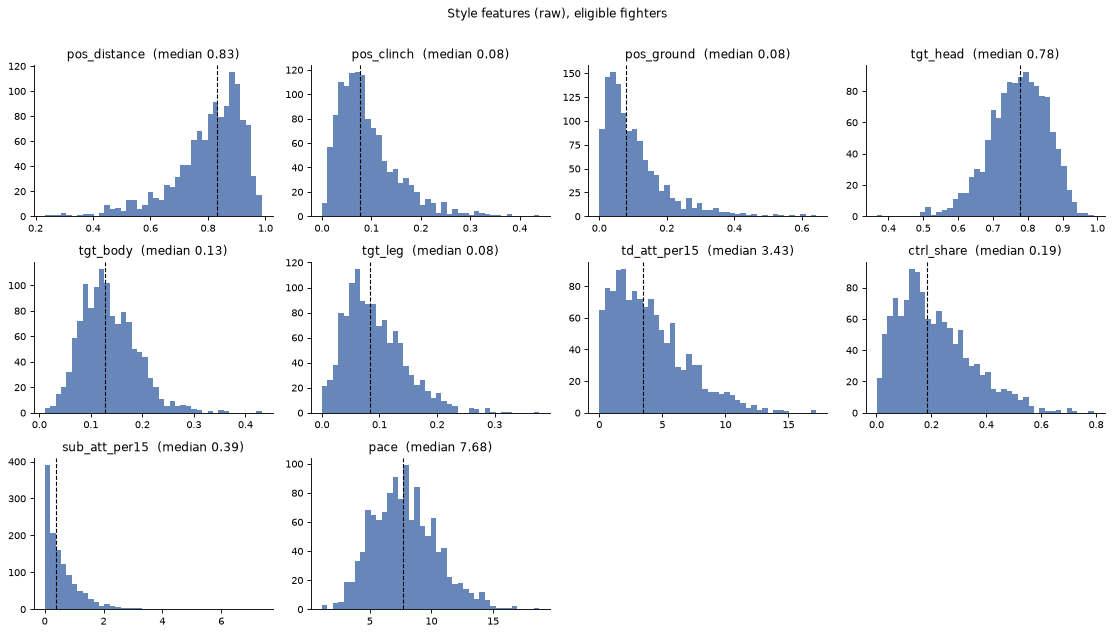

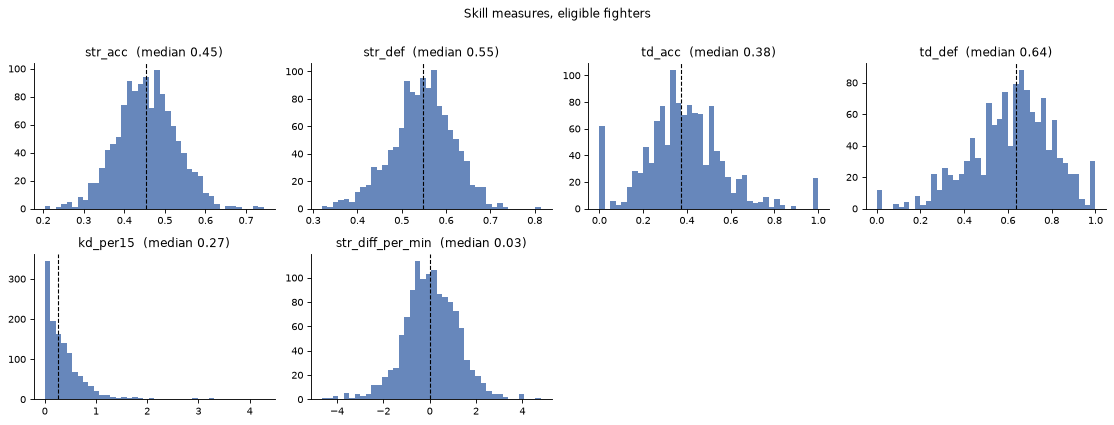

,count,mean,std,min,5%,25%,50%,75%,95%,max
pos_distance,1240.0,0.803,0.122,2.317e-01,0.548,0.747,0.830,0.893,0.943,0.988
pos_clinch,1240.0,0.093,0.062,0.000e+00,0.021,0.049,0.078,0.120,0.213,0.439
pos_ground,1240.0,0.104,0.091,0.000e+00,0.012,0.041,0.078,0.135,0.291,0.643
tgt_head,1240.0,0.773,0.083,3.659e-01,0.629,0.721,0.779,0.834,0.896,0.990
tgt_body,1240.0,0.135,0.054,1.038e-02,0.060,0.095,0.128,0.169,0.225,0.432
tgt_leg,1240.0,0.092,0.053,0.000e+00,0.023,0.053,0.083,0.123,0.190,0.377
td_att_per15,1240.0,3.996,2.905,0.000e+00,0.421,1.719,3.434,5.649,9.775,17.217
ctrl_share,1240.0,0.212,0.134,2.222e-04,0.037,0.112,0.185,0.295,0.473,0.792
sub_att_per15,1240.0,0.583,0.678,0.000e+00,0.000,0.117,0.394,0.839,1.810,7.381
pace,1240.0,7.812,2.599,1.119e+00,3.895,5.904,7.678,9.482,12.419,18.738


In [3]:
def hist_grid(df, cols, title, bins=40):
    fig, axes = plt.subplots(int(np.ceil(len(cols) / 4)), 4, figsize=(14, 2.6 * int(np.ceil(len(cols) / 4))))
    for ax, c in zip(axes.flat, cols):
        x = df[c].dropna()
        ax.hist(x, bins=bins, color="#4C72B0", alpha=0.85)
        ax.axvline(x.median(), color="k", lw=1, ls="--")
        ax.set_title(f"{c}  (median {x.median():.2f})")
    for ax in list(axes.flat)[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, y=1.01, fontsize=11)
    fig.tight_layout()
    plt.show()

hist_grid(elig, STYLE, "Style features (raw), eligible fighters")
hist_grid(elig, SKILL, "Skill measures, eligible fighters")
display(elig[STYLE + SKILL].describe(percentiles=[.05, .25, .5, .75, .95]).T)

### By weight class

Raw (unstandardized) values. The within-division z-scores remove these differences by construction.

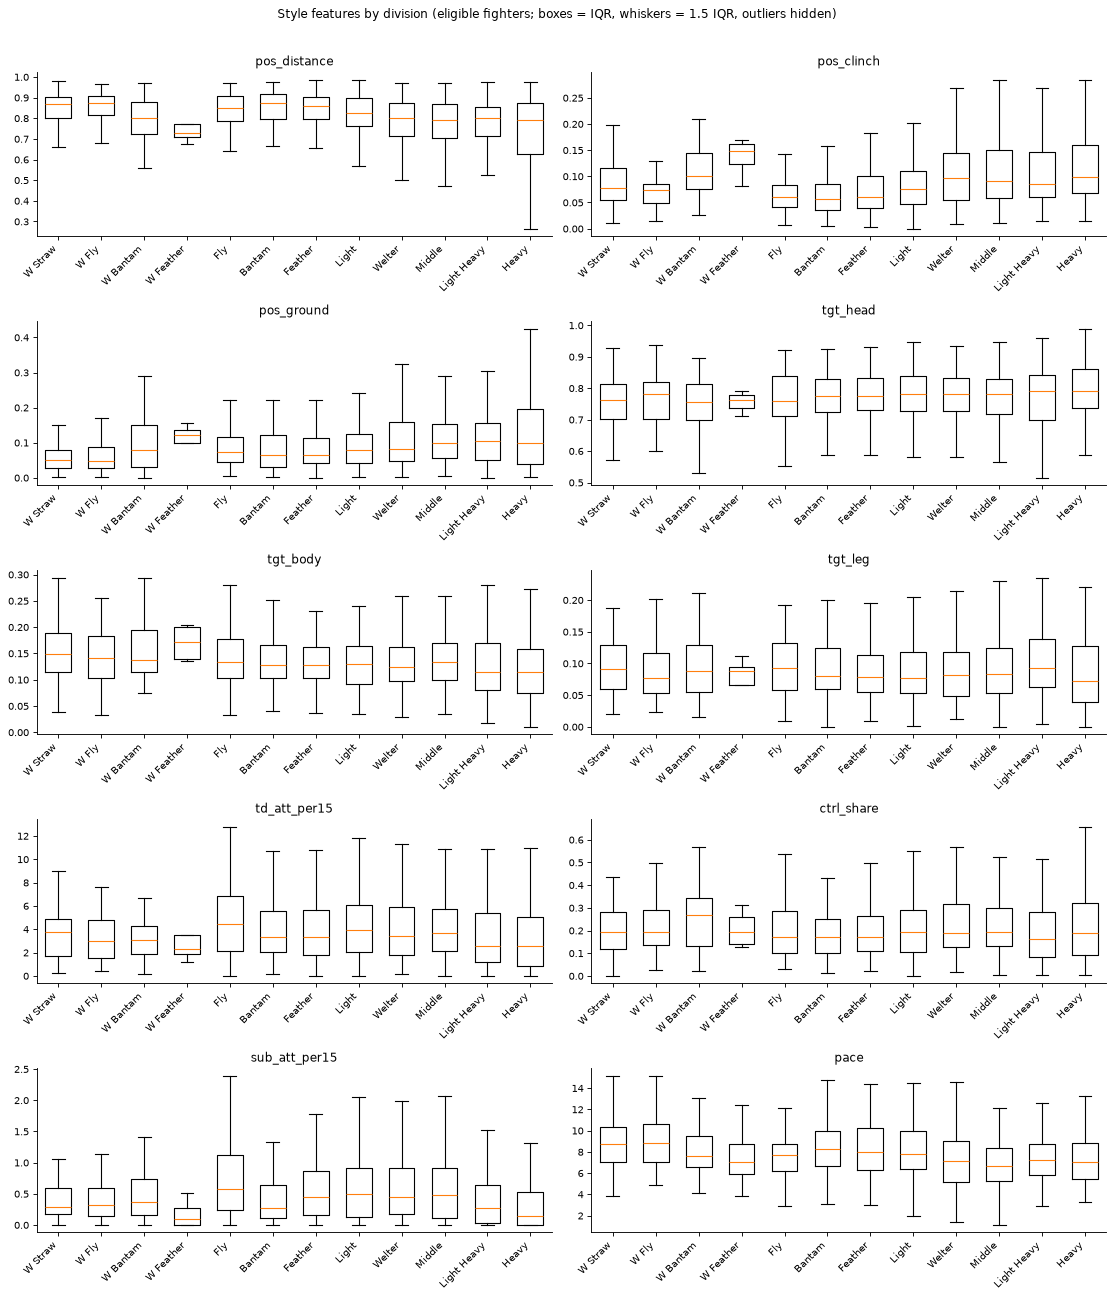

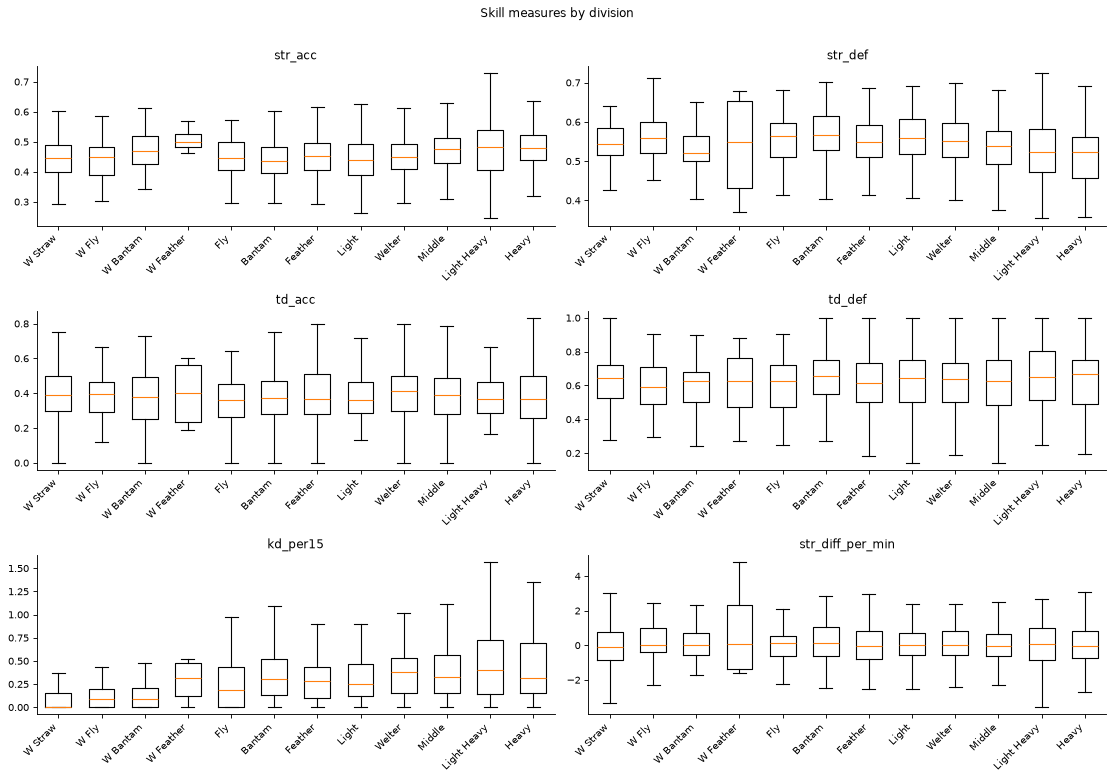

,fighters,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace,str_acc,str_def,td_acc,td_def,kd_per15,str_diff_per_min
division,,,,,,,,,,,,,,,,,
Women's Strawweight,63,0.869,0.077,0.050,0.764,0.149,0.091,3.769,0.194,0.291,8.756,0.445,0.544,0.391,0.641,0.000,-0.092
Women's Flyweight,46,0.876,0.073,0.049,0.781,0.142,0.077,3.027,0.192,0.316,8.880,0.449,0.560,0.394,0.590,0.091,0.023
Women's Bantamweight,41,0.802,0.100,0.078,0.755,0.137,0.087,3.063,0.268,0.365,7.620,0.468,0.521,0.379,0.625,0.092,0.040
Women's Featherweight,4,0.729,0.148,0.123,0.761,0.171,0.088,2.339,0.193,0.098,7.059,0.499,0.548,0.399,0.629,0.315,0.092
Flyweight,74,0.850,0.061,0.074,0.758,0.134,0.093,4.424,0.170,0.585,7.727,0.447,0.564,0.359,0.625,0.184,0.116
Bantamweight,120,0.874,0.056,0.066,0.775,0.129,0.080,3.353,0.173,0.280,8.251,0.435,0.566,0.375,0.655,0.306,0.149
Featherweight,128,0.859,0.061,0.064,0.775,0.129,0.078,3.332,0.169,0.454,8.027,0.451,0.550,0.367,0.615,0.278,-0.068
Lightweight,206,0.826,0.076,0.080,0.781,0.129,0.078,3.929,0.192,0.489,7.819,0.438,0.560,0.360,0.641,0.254,0.021
Welterweight,186,0.803,0.096,0.082,0.783,0.124,0.082,3.439,0.190,0.451,7.117,0.451,0.552,0.413,0.638,0.380,0.023


In [4]:
divs = [d for d in DIV_ORDER if d in set(elig["division"])]
def box_by_div(cols, title):
    fig, axes = plt.subplots(int(np.ceil(len(cols) / 2)), 2, figsize=(14, 3.2 * int(np.ceil(len(cols) / 2))))
    for ax, c in zip(axes.flat, cols):
        data = [elig.loc[elig["division"] == d, c].dropna() for d in divs]
        ax.boxplot(data, showfliers=False, widths=0.6)
        ax.set_xticks(range(1, len(divs) + 1), [d.replace("Women's ", "W ").replace("weight", "") for d in divs], rotation=45, ha="right")
        ax.set_title(c)
    for ax in list(axes.flat)[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, y=1.01, fontsize=11)
    fig.tight_layout()
    plt.show()

box_by_div(STYLE, "Style features by division (eligible fighters; boxes = IQR, whiskers = 1.5 IQR, outliers hidden)")
box_by_div(SKILL, "Skill measures by division")
med = elig.groupby("division")[STYLE + SKILL].median().reindex(divs)
med.insert(0, "fighters", elig["division"].value_counts().reindex(divs))
display(med)

## 3. Correlations

Computed on eligible fighters. Style features use their within-division z-scores (the clustering inputs). Skill measures are also
z-scored within the same groups here, so division differences don't create spurious correlations. Pearson correlation.

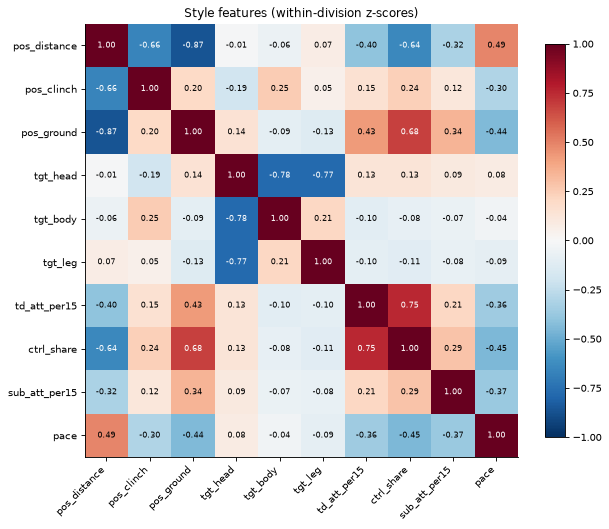

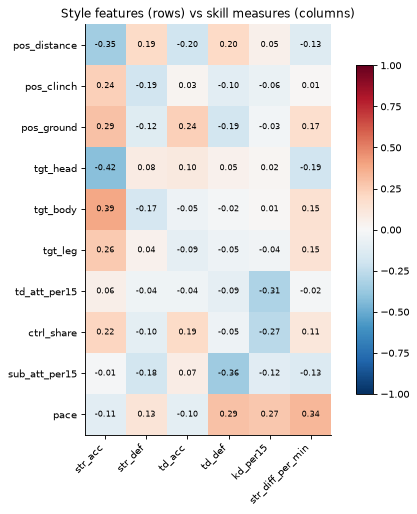

In [5]:
zs = elig[[f"z_{c}" for c in STYLE]].set_axis(STYLE, axis=1)
grp = elig["std_group"]
zk = elig[SKILL].groupby(grp).transform(lambda s: (s - s.mean()) / s.std(ddof=0))

def heat(m, title, figsize):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=45, ha="right")
    ax.set_yticks(range(m.shape[0]), m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else "black")
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

style_corr = zs.corr()
heat(style_corr, "Style features (within-division z-scores)", (8, 7))
cross = pd.concat([zs, zk], axis=1).corr().loc[STYLE, SKILL]
heat(cross, "Style features (rows) vs skill measures (columns)", (6.5, 6.5))

In [6]:
pairs = style_corr.where(np.triu(np.ones(style_corr.shape, bool), 1)).stack().rename("r").reset_index()
pairs = pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index)
print("Strongest style-style correlations (mix shares are compositional, so some negatives are built in):")
display(pairs.head(10).reset_index(drop=True))
cp = cross.stack().rename("r").reset_index().rename(columns={"level_0": "style", "level_1": "skill"})
print("Strongest style-skill correlations:")
display(cp.reindex(cp["r"].abs().sort_values(ascending=False).index).head(10).reset_index(drop=True))

Strongest style-style correlations (mix shares are compositional, so some negatives are built in):


,level_0,level_1,r
0,pos_distance,pos_ground,-0.866
1,tgt_head,tgt_body,-0.778
2,tgt_head,tgt_leg,-0.774
3,td_att_per15,ctrl_share,0.753
4,pos_ground,ctrl_share,0.683
5,pos_distance,pos_clinch,-0.660
6,pos_distance,ctrl_share,-0.644
7,pos_distance,pace,0.489
8,ctrl_share,pace,-0.447
9,pos_ground,pace,-0.438


Strongest style-skill correlations:


,style,skill,r
0,tgt_head,str_acc,-0.419
1,tgt_body,str_acc,0.388
2,sub_att_per15,td_def,-0.358
3,pos_distance,str_acc,-0.350
4,pace,str_diff_per_min,0.336
5,td_att_per15,kd_per15,-0.308
6,pos_ground,str_acc,0.294
7,pace,td_def,0.294
8,pace,kd_per15,0.270
9,ctrl_share,kd_per15,-0.270


## 4. Highest and lowest 10 fighters on each feature

Eligible fighters, raw values.

In [7]:
def extremes(col):
    d = elig.dropna(subset=[col])
    cols = ["fighter_name", "division", "n_fights", col]
    top = d.nlargest(10, col)[cols].reset_index(drop=True)
    bot = d.nsmallest(10, col)[cols].reset_index(drop=True)
    t = pd.concat({"highest": top, "lowest": bot}, axis=1)
    t.index = range(1, 11)
    return t

for col in STYLE + SKILL:
    print(f"\n=== {col} ===")
    display(extremes(col))


=== pos_distance ===


highest                                                       lowest                                         
        fighter_name             division n_fights pos_distance      fighter_name           division n_fights pos_distance
1           Nam Phan        Featherweight        8        0.988     Jason Lambert  Light Heavyweight        8        0.232
2      Kyle Prepolec          Lightweight        5        0.983       Ian Freeman        Heavyweight        6        0.265
3       Austin Lingo        Featherweight        5        0.983   Jailton Almeida        Heavyweight       11        0.275
4     Alice Ardelean  Women's Strawweight        5        0.979     Renato Sobral  Light Heavyweight       10        0.290
5        Andre Ewell         Bantamweight        9        0.978      Brock Lesnar        Heavyweight        8        0.301
6       Rodrigo Damm          Lightweight        7        0.977      Tony DeSouza       Welterweight        6        0.302
7   Brendson Ribeiro    Light Heavyweight        8        0.977     Matt Lindland       Middleweight       12        0.310
8       Emily Ducote  Women's Strawweight        5        0.976   Ricco Rodriguez        Heavyweight        7        0.360
9       Alatengheili         Bantamweight        9        0.975        Matt Grice        Lightweight        7        0.367
10      Justin Ledet    Light Heavyweight        7        0.975  Bartosz Fabinski       Middleweight        6        0.373


=== pos_clinch ===


highest                                                   lowest                                   
        fighter_name           division n_fights pos_clinch      fighter_name       division n_fights pos_clinch
1       Ken Shamrock  Light Heavyweight        5      0.439         Paul Sass    Lightweight        5      0.000
2        Rob Kimmons       Middleweight        7      0.383          Nam Phan  Featherweight        8      0.004
3        Josh Samman       Middleweight        5      0.380      Alatengheili   Bantamweight        9      0.006
4       Terry Martin       Middleweight        6      0.361   Matheus Nicolau      Flyweight       11      0.006
5       Josh Barnett        Heavyweight       10      0.344     Lucas Almeida  Featherweight        6      0.008
6   Bartosz Fabinski       Middleweight        6      0.337     Marlon Moraes   Bantamweight       11      0.008
7       Jorge Rivera       Middleweight       15      0.332     Edgar Chairez      Flyweight        7      0.009
8     Marvin Eastman  Light Heavyweight        5      0.327    Raul Rosas Jr.   Bantamweight        7      0.009
9     Antoni Hardonk        Heavyweight        8      0.325  Michael Chandler    Lightweight        8      0.010
10    Paul Buentello        Heavyweight        6      0.319     Carlos Prates   Welterweight        8      0.010


=== pos_ground ===


highest                                                          lowest                                          
        fighter_name             division n_fights pos_ground           fighter_name              division n_fights pos_ground
1    Jailton Almeida          Heavyweight       11      0.643         Marvin Eastman     Light Heavyweight        5      0.000
2      Renato Sobral    Light Heavyweight       10      0.610        Akira Corassani         Featherweight        6      0.000
3       Brock Lesnar          Heavyweight        8      0.598            Shane Young         Featherweight        7      0.000
4       Tony DeSouza         Welterweight        6      0.570  Jacqueline Cavalcanti  Women's Bantamweight        6      0.000
5    Ricco Rodriguez          Heavyweight        7      0.532              Maheshate           Lightweight        6      0.001
6        Ian Freeman          Heavyweight        6      0.520           Austin Lingo         Featherweight        5      0.001
7      Jason Lambert    Light Heavyweight        8      0.520        Danielle Taylor   Women's Strawweight        5      0.001
8   Jaqueline Amorim  Women's Strawweight        7      0.498         Lukasz Brzeski           Heavyweight        7      0.002
9        Matt Hughes         Welterweight       24      0.465           Justin Ledet     Light Heavyweight        7      0.002
10       Frank Trigg         Welterweight        7      0.452    Gabriella Fernandes     Women's Flyweight        6      0.002

... (22 outputs left out)


=== kd_per15 ===


highest                                          lowest                                       
      fighter_name      division n_fights kd_per15    fighter_name             division n_fights kd_per15
1   Drew McFedries  Middleweight        9    4.272      Davi Ramos          Lightweight        7      0.0
2    Chris Daukaus   Heavyweight        8    3.536      Sean Sherk          Lightweight       12      0.0
3     Tom Aspinall   Heavyweight       10    3.270     Artem Lobov        Featherweight        7      0.0
4    Ateba Gautier  Middleweight        5    3.267    Emily Ducote  Women's Strawweight        5      0.0
5       Uros Medic  Welterweight       11    3.203    Jorge Gurgel          Lightweight        7      0.0
6    Manuel Torres   Lightweight        7    2.927     Rob Kimmons         Middleweight        7      0.0
7      Todd Duffee   Heavyweight        6    2.915  Marvin Eastman    Light Heavyweight        5      0.0
8    Carlos Prates  Welterweight        8    2.325   Kailin Curran  Women's Strawweight        7      0.0
9   Mauricio Ruffy   Lightweight        6    2.058   Chris Padilla          Lightweight        5      0.0
10  Gilbert Urbina  Welterweight        5    2.044      CJ Vergara            Flyweight        8      0.0


=== str_diff_per_min ===


highest                                                                   lowest                                               
          fighter_name               division n_fights str_diff_per_min            fighter_name             division n_fights str_diff_per_min
1    Cristiane Justino  Women's Featherweight        7            4.798            Ken Shamrock    Light Heavyweight        5           -4.646
2       Cain Velasquez            Heavyweight       15            4.080          Daniel Lacerda            Flyweight        6           -4.333
3            Wang Cong      Women's Flyweight        6            4.023          Louis Gaudinot            Flyweight        5           -4.088
4         Tom Aspinall            Heavyweight       10            4.012             Jimmy Flick            Flyweight        6           -4.025
5      Navajo Stirling      Light Heavyweight        6            3.945  Montserrat Conejo Ruiz  Women's Strawweight        5           -3.981
6          Todd Duffee            Heavyweight        6            3.255             David Heath    Light Heavyweight        5           -3.682
7    Terrance McKinney            Lightweight       14            3.193           Kyle Prepolec          Lightweight        5           -3.587
8           Ciryl Gane            Heavyweight       14            3.095            Tresean Gore         Middleweight        7           -3.586
9      Michael Morales           Welterweight        7            3.035          Ike Villanueva    Light Heavyweight        6           -3.581
10  Joanna Jedrzejczyk    Women's Strawweight       15            3.034           Elvis Sinosic    Light Heavyweight        7           -3.473

## 5. Notes

- The position mix and target mix each sum to 1, so within each mix the three shares are linearly dependent. Every mix has 2 free
  dimensions, not 3. Worth deciding before clustering whether to keep all three shares (which double-counts one dimension) or drop one.
- Shares and rates are pooled over fights (see the spec), so fighters with many short fights don't get extreme values from a single fight.